In [ ]:
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

# 吹込管のメンズール関数定義

吹込管のメンズールを関数で定義することを考える。

$x$ はマウスピースの出口(差し込んだマウスピースの先端)からの芯線に沿った長さ [mm]、$D$ は内径 [mm]。
ここではマウスピースより先のメンズールだけを扱う。マウスピースを差し込むシャンク部分は含めない。

与える条件は 3 つ:

1. $D(0) = d_0$(マウスピースの出口)
2. $D(L) = d_1$(太い側。ここまでで広がり終わる)
3. $D(L_2) = d_2$($0 < L_2 < L$)

はじめに 4 パラメータの $D(x) = a\,(x+b)^p + d$ で考え、3 パラメータの $D(x) = a\,(x+b)^p$ に減らす。
さらにそれを、両端の径と形のパラメータ $k$ ひとつで書く形

$$
D(x) = d_0 \left(\frac{d_1}{d_0}\right)^{\varphi(x/L)},\qquad
\varphi(u) = \frac{\ln(1 + k\,u)}{\ln(1 + k)}
$$

に直す。各節の終わりに、その形での実例を計算する。

## 条件の値

### シャンク部分から $d_0$ を決める

実際の吹込管には、マウスピースを差し込むシャンク部分がある。通常、内径は入口の 8.3〜8.4 から、
マウスピースの差込長さ(18〜20 mm)にわたってテーパー率 0.03(長さ 1 mm あたりの直径の減り)で細くなる。
マウスピースの出口(= この式の $x=0$)での径は

$$
d_0 = D_\mathrm{shank} - 0.03 \times L_\mathrm{insert}
$$

で、8.4 から始めて差込長さ 18 なら $8.4 - 0.54 = 7.86$ になる。

In [ ]:
d_shank = mo.ui.slider(8.3, 8.4, step=0.01, value=8.4, show_value=True, label="シャンクの入口の内径 D_shank")
l_insert = mo.ui.slider(18.0, 20.0, step=0.5, value=18.0, show_value=True, label="マウスピースの差込長さ L_insert")
mo.vstack([d_shank, l_insert])

<marimo-slider data-initial-value='8.4' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eシャンクの入口の内径 D_shank\u003c/span\u003e\u003c/span\u003e"' data-start='8.3' data-stop='8.4' data-step='0.01' data-steps='[]' data-debounce='false' data-disabled='false' data-orientation='"horizontal"' data-show-value='true' data-include-input='false' data-full-width='false'> <marimo-slider data-initial-value='18.0' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eマウスピースの差込長さ L_insert\u003c/span\u003e\u003c/span\u003e"' data-start='18.0' data-stop='20.0' data-step='0.5' data-steps='[]' data-debounce='false' data-disabled='false' data-orientation='"horizontal"' data-show-value='true' data-include-input='false' data-full-width='false'>

In [ ]:
TAPER_SHANK = 0.03  # シャンクのテーパー率(直径の減り / 長さ)
d0 = d_shank.value - TAPER_SHANK * l_insert.value  # マウスピースの出口の内径(x = 0)
mo.md(f"$d_0$ = {d_shank.value:g} − {TAPER_SHANK:g} × {l_insert.value:g} = **{d0:.4f}**")

$d_0$ = 8.4 − 0.03 × 18 = **7.8600**

### そのほかの条件

$L, d_1$ は今の吹込管(`mouthpipe_try.py`: 450 で 12)と同じにした。$L_2, d_2$ は仮の値なので置き換える。

In [ ]:
L_in = mo.ui.number(value=450.0, step=1.0, label="L(太い側の位置)")
d1_in = mo.ui.number(value=12.0, step=0.01, label="d1(太い側の内径)")
L2_in = mo.ui.number(value=150.0, step=1.0, label="L2(途中の位置、仮)")
d2_in = mo.ui.number(value=9.6, step=0.01, label="d2(途中の内径、仮)")
mo.vstack([L_in, d1_in, L2_in, d2_in])

In [ ]:
L, d1, L2, d2 = L_in.value, d1_in.value, L2_in.value, d2_in.value
xx = np.linspace(0.0, L, int(L) + 1)  # 1 mm おき

## 4 パラメータの形: $D(x) = a\,(x+b)^p + d$

$x = 0$ で $a\,b^p + d$ になる。$b \ge 0$ なら $[0, L]$ で $x+b>0$。

**指数 $p$ について**: $p = 1$ のとき $D$ は $x$ の 1 次式で、単純な直線のテーパーになる。
吹込管は基本的に中膨らみ(直線のテーパーより太い、上に凸)の形なので、**$0 < p < 1$** とする。
$p$ が小さいほど入口側で急に広がり、太い側では緩やかになる。

### $p$ を決めたときの $a, b, d$

3 つの条件を式で書くと

$$
d_0 = a\,b^p + d,\qquad d_1 = a\,(L+b)^p + d,\qquad d_2 = a\,(L_2+b)^p + d
$$

条件 2 から条件 1 を、条件 3 から条件 1 を引くと $d$ が消える。

$$
d_1 - d_0 = a\left[(L+b)^p - b^p\right],\qquad
d_2 - d_0 = a\left[(L_2+b)^p - b^p\right]
$$

2 つ目を 1 つ目で割ると $a$ も消え、$b$ だけの式になる。左辺の比を $r$ と置く。

$$
r \equiv \frac{d_2-d_0}{d_1-d_0} = \frac{(L_2+b)^p - b^p}{(L+b)^p - b^p}
$$

$r$ は、全体の広がり $d_1-d_0$ のうち、$L_2$ までにどれだけ広がったかの割合で、条件の値だけで決まる。

- $p = 1$ なら右辺は $b$ によらず $L_2/L$。直線のテーパーは $r = L_2/L$ のときだけ 3 点を通る。
- $0 < p < 1$ なら右辺は $b=0$ で $(L_2/L)^p$、$b\to\infty$ で $L_2/L$(直線に近づく)。
  したがって解があるのは $L_2/L < r < (L_2/L)^p$ のとき。

$b$ が決まれば

$$
a = \frac{d_1-d_0}{(L+b)^p - b^p},\qquad d = d_0 - a\,b^p
$$

3 条件で $a, b, d$ は $p$ の関数として決まり、$p$ の分の自由度が 1 つ残る。

### 実例: $p$ を変えて比べる

3 条件を満たしたまま $p$ を 0.1〜0.7 で動かす。

In [ ]:
def solve4(pv):
    """4 パラメータの形で、p を与えて 3 条件を満たす (a, b, d) を返す。"""
    _r = (d2 - d0) / (d1 - d0)

    def g(b):
        return ((L2 + b) ** pv - b**pv) / ((L + b) ** pv - b**pv) - _r

    _b = brentq(g, 0.0, 1e9, xtol=1e-12, rtol=1e-15, maxiter=500)
    _a = (d1 - d0) / ((L + _b) ** pv - _b**pv)
    return _a, _b, d0 - _a * _b**pv

_r = (d2 - d0) / (d1 - d0)
p_lim = np.log(_r) / np.log(L2 / L)  # b = 0 になる p。これより小さい p で解がある
ps4 = [pv for pv in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7) if pv < p_lim]
family4 = {pv: solve4(pv) for pv in ps4}
ys4 = np.array([_a * (xx + _b) ** pv + _d for pv, (_a, _b, _d) in family4.items()])
spread4 = ys4.max(axis=0) - ys4.min(axis=0)
_rows = "\n".join(f"| {pv:.1f} | {_a:.5g} | {_b:.5g} | {_d:.5g} |" for pv, (_a, _b, _d) in family4.items())
mo.md(
    f"$r$ = {_r:.6f}(直線なら $L_2/L$ = {L2 / L:.6f})  \n"
    f"解のある $p$ の範囲: 0 < $p$ < {p_lim:.6f}\n\n"
    "| p | a | b | d |\n|---|---|---|---|\n" + _rows
    + f"\n\n径の差の最大: **{spread4.max():.4f} mm**(x = {xx[spread4.argmax()]:g})"
)

$r$ = 0.420290(直線なら $L_2/L$ = 0.333333)  
解のある $p$ の範囲: 0 < $p$ < 0.789005

| p | a | b | d |
|---|---|---|---|
| 0.1 | 27.019 | 355.98 | -40.76 |
| 0.2 | 6.5613 | 298.51 | -12.651 |
| 0.3 | 2.1512 | 241.54 | -3.298 |
| 0.4 | 0.80493 | 185.34 | 1.3595 |
| 0.5 | 0.32668 | 130.37 | 4.13 |
| 0.6 | 0.14092 | 77.607 | 5.9418 |
| 0.7 | 0.064132 | 29.61 | 7.1728 |

径の差の最大: **0.0429 mm**(x = 47)

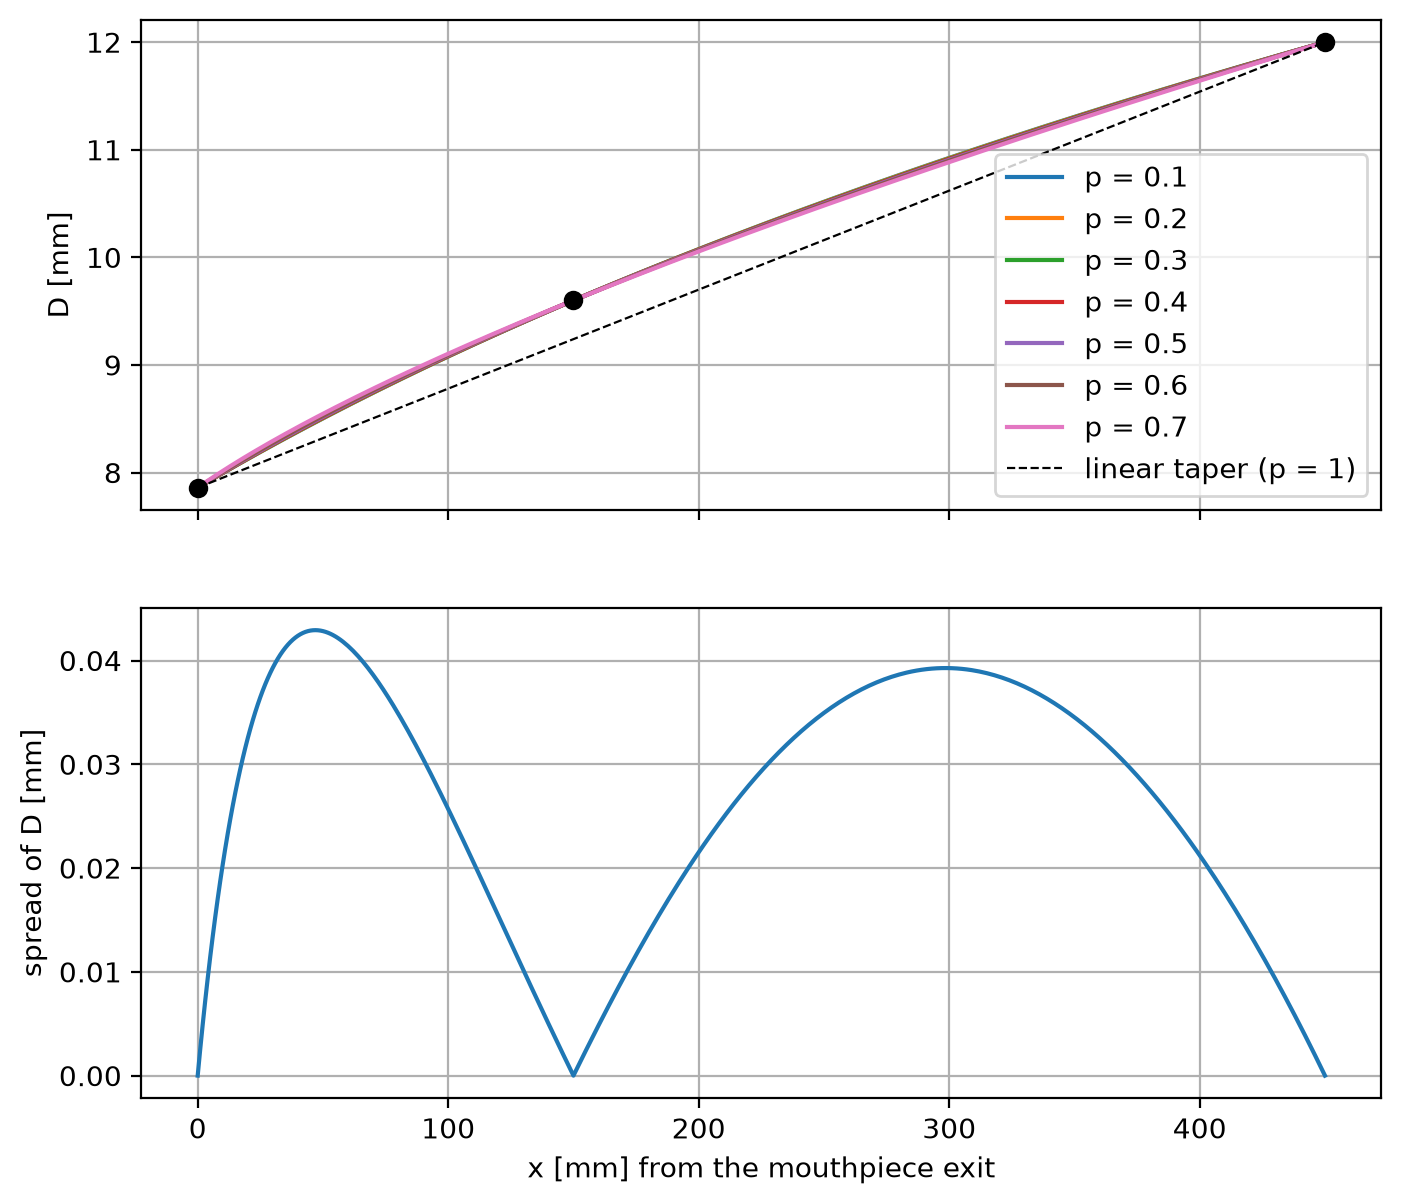

In [ ]:
fig_family, ax_family = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for _pv, _y in zip(ps4, ys4):
    ax_family[0].plot(xx, _y, label=f"p = {_pv:.1f}")
ax_family[0].plot([0, L], [d0, d1], "k--", lw=0.8, label="linear taper (p = 1)")
ax_family[0].plot([0, L2, L], [d0, d2, d1], "ko")
ax_family[0].set_ylabel("D [mm]")
ax_family[0].legend()
ax_family[1].plot(xx, spread4)
ax_family[1].set_ylabel("spread of D [mm]")
ax_family[1].set_xlabel("x [mm] from the mouthpiece exit")
for _ax in ax_family:
    _ax.grid(True)
fig_family

$p$ を大きく変えても、曲線の差は数百分の 1 mm しかない。動くのは $b$ と $d$ の組み合わせで、形はほとんど変わらない。
また $p$ が小さいと $d<0$ になる。

したがって 4 つ目のパラメータは要らない。$d = 0$ とした 3 パラメータの形を使う。
これは上の 4 パラメータの族のうち、$d = 0$ になる 1 本にあたる。

## 3 パラメータの形: $D(x) = a\,(x+b)^p$

3 つの条件で $a, b, p$ が決まる。条件 2・3 をそれぞれ条件 1 で割ると $a$ が消える。

$$
\left(1 + \frac{L}{b}\right)^p = \frac{d_1}{d_0},\qquad
\left(1 + \frac{L_2}{b}\right)^p = \frac{d_2}{d_0}
$$

対数を取って 2 つ目を 1 つ目で割ると $p$ も消え、$b$ だけの式になる。左辺の比を $q$ と置く。

$$
q \equiv \frac{\ln(d_2/d_0)}{\ln(d_1/d_0)} = \frac{\ln(1 + L_2/b)}{\ln(1 + L/b)}
$$

$q$ も条件の値だけで決まる。右辺は $b\to\infty$ で $L_2/L$、$b\to 0$ で 1 なので、
$L_2/L < q < 1$ のときに解がある。$b$ が決まれば

$$
p = \frac{\ln(d_1/d_0)}{\ln(1 + L/b)},\qquad a = \frac{d_0}{b^p}
$$

### 実例: 3 点から $a, b, p$ を求める

In [ ]:
def solve3():
    """D(0)=d0, D(L)=d1, D(L2)=d2 を満たす (a, b, p) を返す。"""
    _q = np.log(d2 / d0) / np.log(d1 / d0)
    if not L2 / L < _q < 1:
        raise ValueError(f"解がない: q = {_q:.6f} は ({L2 / L:.6f}, 1) の外")
    _b = brentq(lambda b: np.log1p(L2 / b) / np.log1p(L / b) - _q, 1e-9, 1e9, xtol=1e-12, rtol=1e-15)
    _p = np.log(d1 / d0) / np.log1p(L / _b)
    return d0 / _b**_p, _b, _p

a3, b3, p3 = solve3()
y3 = a3 * (xx + b3) ** p3
_chk = "\n".join(
    f"| {xq:g} | {a3 * (xq + b3) ** p3:.6f} | {dq:g} |" for xq, dq in [(0.0, d0), (L2, d2), (L, d1)]
)
_d = solve4(p3)[2]  # 4 パラメータの形で同じ p
mo.md(
    f"$q$ = {np.log(d2 / d0) / np.log(d1 / d0):.6f}(解のある範囲 {L2 / L:.6f} .. 1)\n\n"
    f"- $a$ = **{a3:.10g}**\n- $b$ = **{b3:.10g}**\n- $p$ = **{p3:.10g}**\n\n"
    "| x | D(x) | 目標 |\n|---|---|---|\n" + _chk
    + f"\n\n4 パラメータの形で同じ $p$ を使うと $d$ = {_d:.3g}(つまり $d = 0$ の 1 本)。"
    f"上の 4 パラメータの族との差の最大: {np.abs(ys4 - y3).max():.4f} mm"
)

$q$ = 0.472624(解のある範囲 0.333333 .. 1)

- $a$ = **1.129075332**
- $b$ = **205.2021839**
- $p$ = **0.3644607712**

| x | D(x) | 目標 |
|---|---|---|
| 0 | 7.860000 | 7.86 |
| 150 | 9.600000 | 9.6 |
| 450 | 12.000000 | 12 |

4 パラメータの形で同じ $p$ を使うと $d$ = -4.44e-15(つまり $d = 0$ の 1 本)。上の 4 パラメータの族との差の最大: 0.0361 mm

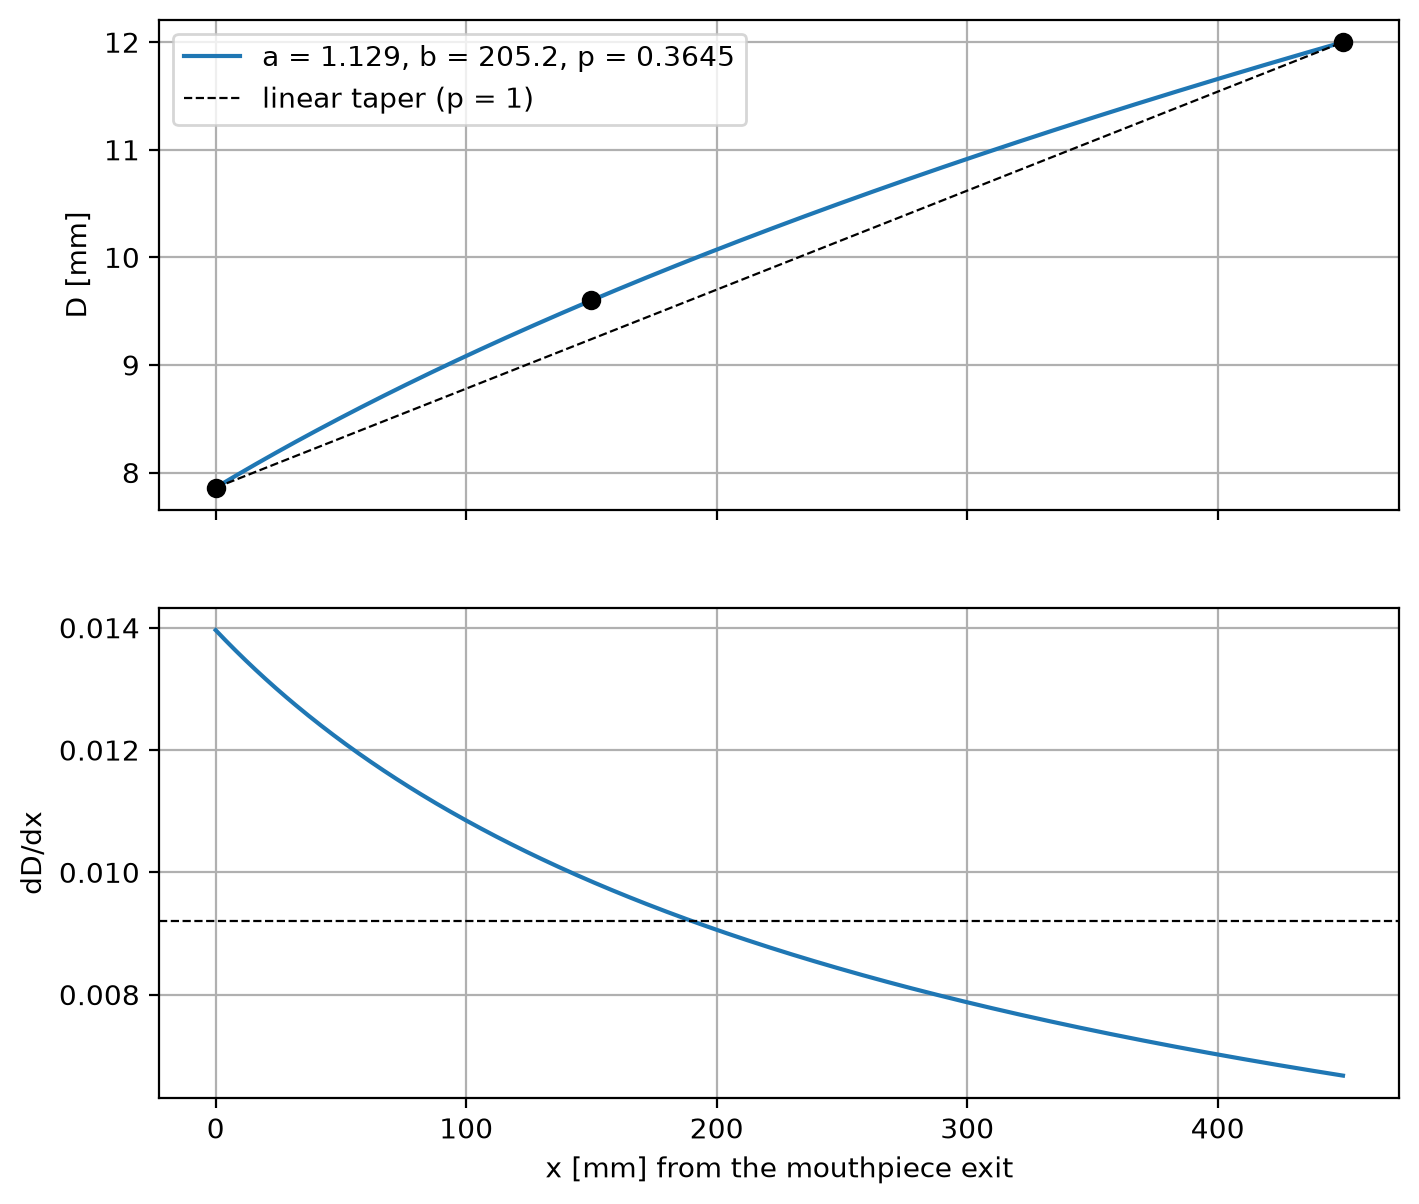

In [ ]:
fig_abp, ax_abp = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
ax_abp[0].plot(xx, y3, label=f"a = {a3:.4g}, b = {b3:.4g}, p = {p3:.4g}")
ax_abp[0].plot([0, L], [d0, d1], "k--", lw=0.8, label="linear taper (p = 1)")
ax_abp[0].plot([0, L2, L], [d0, d2, d1], "ko")
ax_abp[1].plot(xx, a3 * p3 * (xx + b3) ** (p3 - 1.0))
ax_abp[1].axhline((d1 - d0) / L, color="k", ls="--", lw=0.8)
ax_abp[0].set_ylabel("D [mm]")
ax_abp[1].set_ylabel("dD/dx")
ax_abp[1].set_xlabel("x [mm] from the mouthpiece exit")
ax_abp[0].legend()
for _ax in ax_abp:
    _ax.grid(True)
fig_abp

## $k$ の形: $D(x) = d_0\,(d_1/d_0)^{\varphi(x/L)}$

条件 1 から $a\,b^p = d_0$ なので

$$
D(x) = a\,b^p \left(1 + \frac{x}{b}\right)^p = d_0 \left(1 + \frac{x}{b}\right)^p
$$

$u = x/L$(0〜1)、$k = L/b$($>0$)と置くと $D = d_0\,(1 + k\,u)^p$。
条件 2 から $(1+k)^p = d_1/d_0$、すなわち

$$
p = \frac{\ln(d_1/d_0)}{\ln(1+k)}
$$

これを代入すると

$$
\begin{aligned}
D &= d_0\,(1 + k\,u)^p \\
  &= d_0 \exp\!\left[p \ln(1+k\,u)\right] \\
  &= d_0 \exp\!\left[\frac{\ln(d_1/d_0)\ln(1+k\,u)}{\ln(1+k)}\right] \\
  &= d_0 (\frac{d_1}{d_0})^{\frac{\ln(1+k\,u)}{\ln(1+k)}}
\end{aligned}
$$

から

$$
\boxed{\;D(x) = d_0 \left(\frac{d_1}{d_0}\right)^{\varphi(u)},\qquad
\varphi(u) = \frac{\ln(1 + k\,u)}{\ln(1 + k)},\qquad u = \frac{x}{L}\;}
$$

$\varphi(0) = 0$、$\varphi(1) = 1$。両端の径 $d_0, d_1$ がそのまま式に出て、形は $k$ ひとつで決まる。
径の対数を $\ln d_0$ から $\ln d_1$ まで $\varphi(u)$ で補間している形になっている。

$a, b, p$ は $k$ から $b = L/k$、$p = \ln(d_1/d_0)/\ln(1+k)$、$a = d_0/b^p$ と決まる。

| $k$ | 形 | $p$ |
|---|---|---|
| $k \to 0$ | $\varphi = u$。径が一定の比率で増える指数の形(下に凸) | $p \to \infty$ |
| $k = d_1/d_0 - 1$ | 直線のテーパー | $p = 1$ |
| $k > d_1/d_0 - 1$ | 中膨らみ | $p < 1$ |
| $k \to \infty$ | 入口ですぐ太くなる、段に近い形 | $p \to 0$ |

### 3 点の条件

条件 3 は $d_2/d_0 = \left(d_1/d_0\right)^{\varphi(L_2/L)}$、すなわち

$$
\varphi\!\left(\frac{L_2}{L}\right) = q = \frac{\ln(d_2/d_0)}{\ln(d_1/d_0)}
$$

で、3 パラメータの節の $q$ の式そのもの。$\varphi(L_2/L)$ は $k$ について単調に増え、
$k\to 0$ で $L_2/L$、$k\to\infty$ で 1 になるので、$L_2/L < q < 1$ なら $k$ がただ一つ決まる。
中膨らみ($k > d_1/d_0 - 1$)になるのは、$q$ が直線のときの値 $\ln\!\left(1 + (d_1/d_0 - 1)\,L_2/L\right) / \ln(d_1/d_0)$ より大きいとき。

### 傾き

$$
D'(x) = D(x)\,\ln\frac{d_1}{d_0}\cdot\frac{k}{L\,(1+k\,u)\,\ln(1+k)}
$$

### 計算に使う関数

In [ ]:
LN_R = np.log(d1 / d0)  # ln(d1/d0)
K_LIN = d1 / d0 - 1.0  # 直線のテーパーになる k

def phi(u, k):
    """φ(u) = ln(1 + k u) / ln(1 + k)"""
    return np.log1p(k * np.asarray(u, dtype=float)) / np.log1p(k)

def diameter(x, k):
    """D(x) = d0 (d1/d0)^φ(x/L)"""
    return d0 * np.exp(LN_R * phi(np.asarray(x, dtype=float) / L, k))

def slope(x, k):
    """D'(x)"""
    _u = np.asarray(x, dtype=float) / L
    return diameter(x, k) * LN_R * k / (L * (1.0 + k * _u) * np.log1p(k))

def k_to_abp(k):
    """k から 3 パラメータの形の (a, b, p) を返す。"""
    _b = L / k
    _p = LN_R / np.log1p(k)
    return d0 / _b**_p, _b, _p

def solve_k(L2, d2):
    """3 点目 D(L2) = d2 を満たす k を返す(φ(L2/L) = q を ln k について解く)。"""
    _q = np.log(d2 / d0) / LN_R
    if not 0 < L2 < L:
        raise ValueError("0 < L2 < L が必要")
    if not L2 / L < _q < 1:
        raise ValueError(f"解がない: q = {_q:.6f} は ({L2 / L:.6f}, 1) の外")
    _lnk = brentq(lambda m: phi(L2 / L, np.exp(m)) - _q, -30.0, 60.0, xtol=1e-14)
    return float(np.exp(_lnk))

### 実例: 3 点から $k$ を求める

In [ ]:
k_fit = solve_k(L2, d2)
_a, _b, _p = k_to_abp(k_fit)
_q = np.log(d2 / d0) / np.log(d1 / d0)
_q_lin = np.log1p(K_LIN * L2 / L) / np.log(d1 / d0)
_chk = "\n".join(
    f"| {xq:g} | {float(diameter(xq, k_fit)):.6f} | {dq:g} |" for xq, dq in [(0.0, d0), (L2, d2), (L, d1)]
)
mo.md(
    f"$q$ = {_q:.6f}(解のある範囲 {L2 / L:.6f} .. 1、直線なら {_q_lin:.6f})\n\n"
    f"- $k$ = **{k_fit:.10g}**($\\mu = \\ln(k/(d_1/d_0 - 1))$ = {np.log(k_fit / K_LIN):.6f}、直線は $k$ = {K_LIN:.6f}、"
    + ("中膨らみ" if k_fit > K_LIN else "**中膨らみでない**")
    + ")\n"
    f"- 3 パラメータの形に直すと $a$ = {_a:.10g}、$b$ = {_b:.10g}、$p$ = {_p:.10g}"
    f"(3 パラメータの節の値との差: $b$ {_b - b3:.2g}、$p$ {_p - p3:.2g})\n"
    "\n"
    "| x | D(x) | 目標 |\n|---|---|---|\n" + _chk
    + f"\n\n$D'(0)$ = {float(slope(0.0, k_fit)):.6f}、$D'(L)$ = {float(slope(L, k_fit)):.6f}"
)

$q$ = 0.472624(解のある範囲 0.333333 .. 1、直線なら 0.382292)

- $k$ = **2.192959117**($\mu = \ln(k/(d_1/d_0 - 1))$ = 1.426343、直線は $k$ = 0.526718、中膨らみ)
- 3 パラメータの形に直すと $a$ = 1.129075332、$b$ = 205.2021839、$p$ = 0.3644607712(3 パラメータの節の値との差: $b$ -3.7e-13、$p$ -4.4e-16)

| x | D(x) | 目標 |
|---|---|---|
| 0 | 7.860000 | 7.86 |
| 150 | 9.600000 | 9.6 |
| 450 | 12.000000 | 12 |

$D'(0)$ = 0.013960、$D'(L)$ = 0.006675

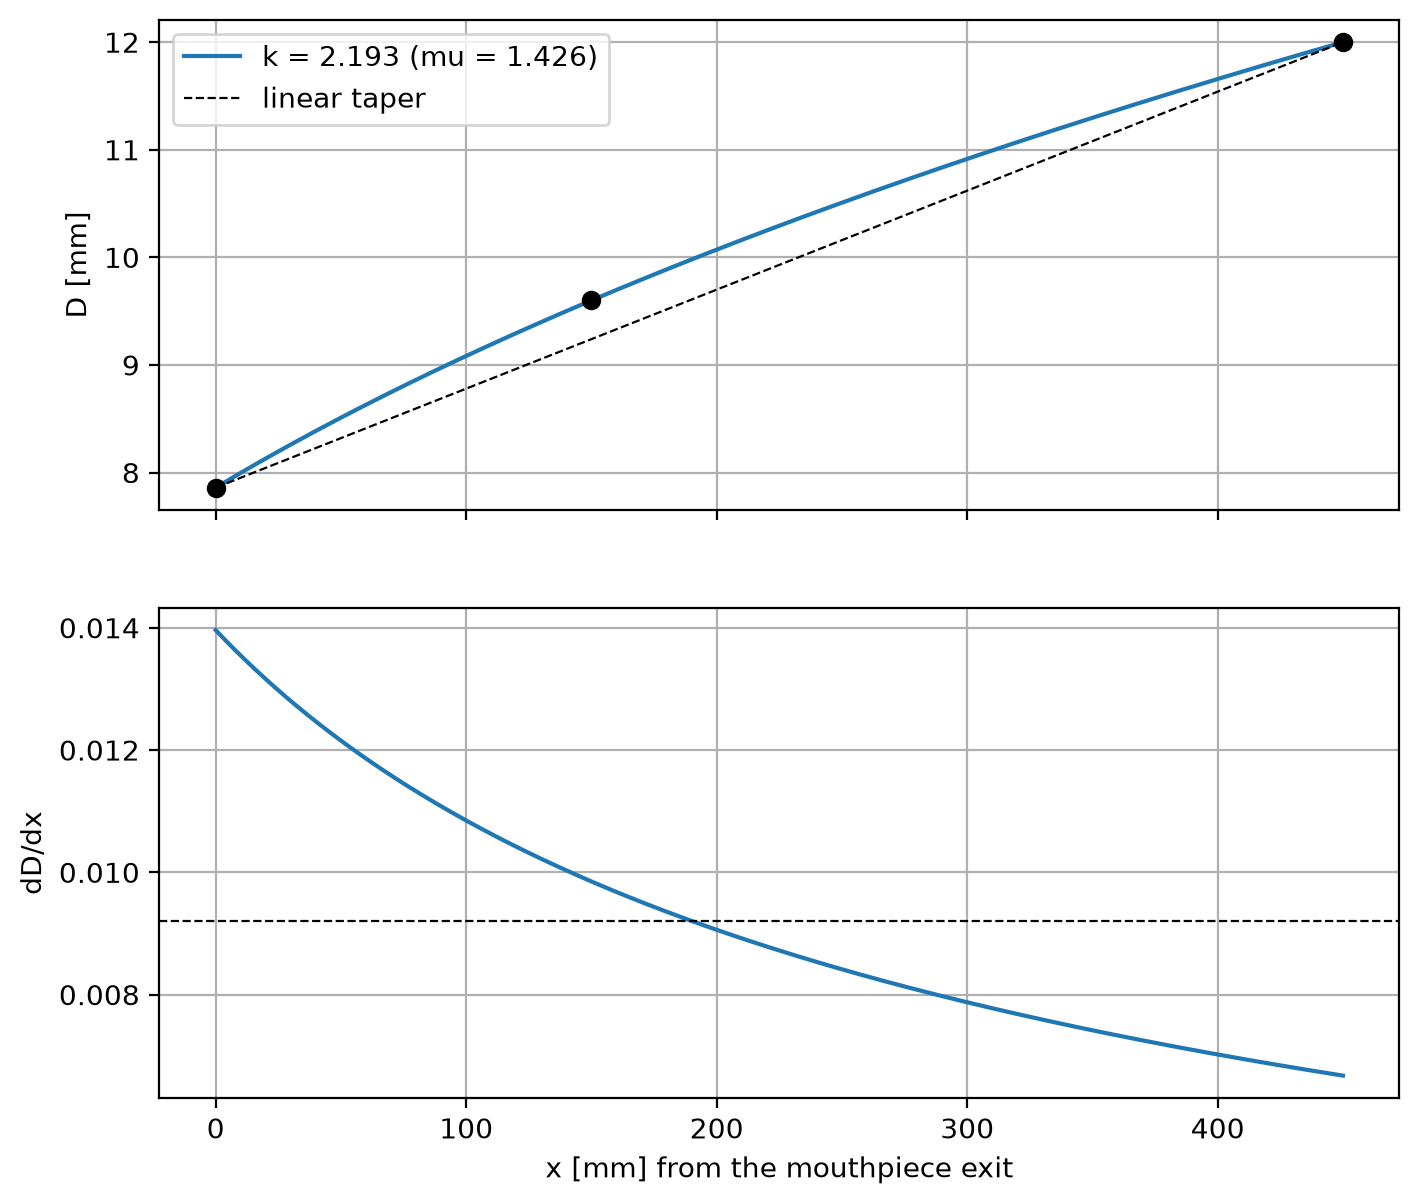

In [ ]:
fig_shape, ax_shape = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
ax_shape[0].plot(xx, diameter(xx, k_fit), label=f"k = {k_fit:.4g} (mu = {np.log(k_fit / K_LIN):.4g})")
ax_shape[0].plot([0, L], [d0, d1], "k--", lw=0.8, label="linear taper")
ax_shape[0].plot([0, L2, L], [d0, d2, d1], "ko")
ax_shape[1].plot(xx, slope(xx, k_fit))
ax_shape[1].axhline((d1 - d0) / L, color="k", ls="--", lw=0.8)
ax_shape[0].set_ylabel("D [mm]")
ax_shape[1].set_ylabel("dD/dx")
ax_shape[1].set_xlabel("x [mm] from the mouthpiece exit")
ax_shape[0].legend()
for _ax in ax_shape:
    _ax.grid(True)
fig_shape

## $\mu$ の形: $k = (d_1/d_0 - 1)\,e^{\mu}$

直線のテーパーになる $k$ は $d_1/d_0 - 1$ で、$d_0, d_1$ によって変わる。
また、形の変わり方は $k$ そのものより $k$ の対数に対して均等に近い。
そこで、$k$ をこの値で割ってから対数を取った

$$
\mu = \ln\frac{k}{d_1/d_0 - 1},\qquad k = \left(\frac{d_1}{d_0} - 1\right) e^{\mu}
$$

を形のパラメータとする。$R = d_1/d_0$ と書くと

$$
D(x) = d_0\,R^{\varphi(u)},\qquad
\varphi(u) = \frac{\ln\left(1 + (R-1)\,e^{\mu}\,u\right)}{\ln\left(1 + (R-1)\,e^{\mu}\right)}
$$

$\mu = 0$ なら $\varphi(u) = \ln\left(1 + (R-1)\,u\right)/\ln R$ で、
$D = d_0\left(1 + (R-1)\,u\right) = d_0 + (d_1 - d_0)\,u$ と直線のテーパーになる。

3 パラメータの形に戻すと $D = a\,(x+b)^p$、$p = \ln R/\ln(1+k)$ で、べき関数なので区間全体で
$p < 1$ なら上に凸、$p > 1$ なら下に凸。$p < 1$ は $k > R - 1$、すなわち $\mu > 0$ と同じなので、
凸の向きは $\mu$ の符号で決まり、$d_0, d_1$ によらない。

| $\mu$ | $p$ | 形 |
|---|---|---|
| $\mu < 0$ | $p > 1$ | 下に凸($\mu \to -\infty$ で指数の形 $D = d_0 R^u$) |
| $\mu = 0$ | $p = 1$ | 直線のテーパー |
| $\mu > 0$ | $p < 1$ | 上に凸、中膨らみ($\mu \to \infty$ で段に近い形) |

$\mu > 0$ の側では、$\mu$ の変化に対して形がほぼ均等に変わる。
$\mu < 0$ の側は指数の形に近づいて頭打ちになるので均等ではないが、吹込管では $\mu > 0$ しか使わない。

### 実例: $\mu$ を変えて比べる

$D(0) = d_0$、$D(L) = d_1$ だけを満たし、$\mu$ を 0(直線)から 0.5 ずつ増やす。
曲線どうしの径の差が最も大きい位置を取り上げ、その位置での値も表にする。

In [ ]:
mu_list = [0.5 * i for i in range(7)]  # μ = 0(直線)から 0.5 ずつ
ys_mu = np.array([diameter(xx, K_LIN * np.exp(_m)) for _m in mu_list])
spread_mu = ys_mu.max(axis=0) - ys_mu.min(axis=0)
i_max = int(spread_mu.argmax())
x_max = float(xx[i_max])

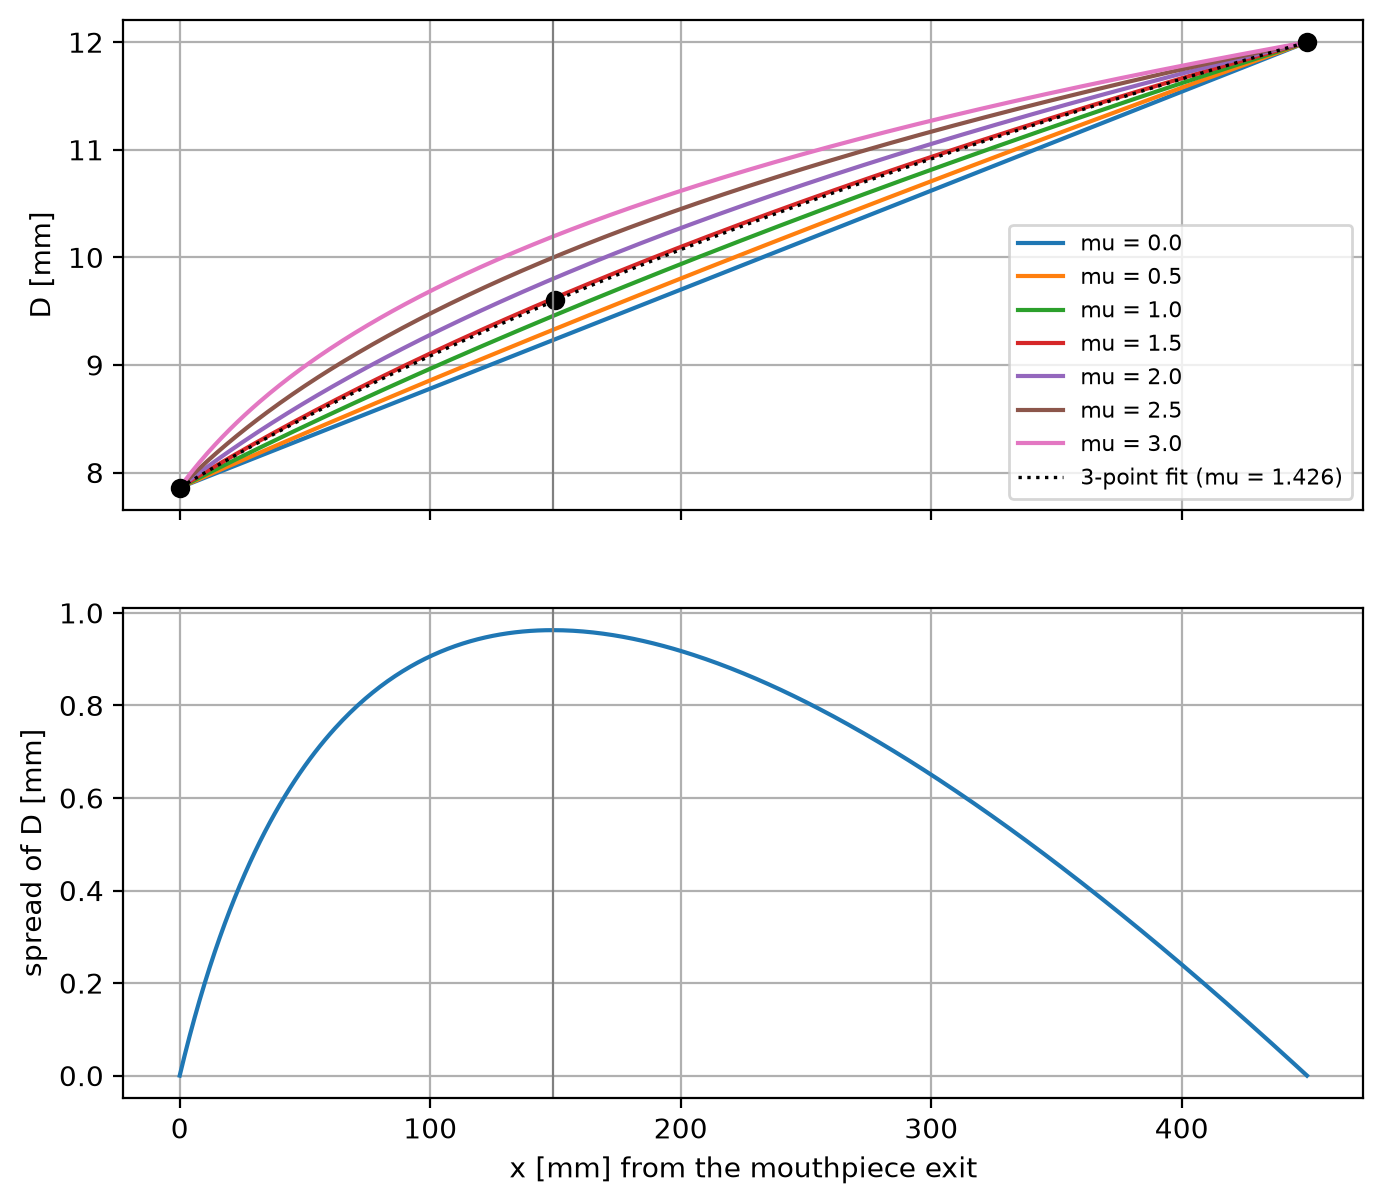

In [ ]:
fig_mu, ax_mu = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for _m, _y in zip(mu_list, ys_mu):
    ax_mu[0].plot(xx, _y, label=f"mu = {_m:.1f}")
ax_mu[0].plot(xx, diameter(xx, k_fit), "k:", lw=1.2, label=f"3-point fit (mu = {np.log(k_fit / K_LIN):.3f})")
ax_mu[0].plot([0, L2, L], [d0, d2, d1], "ko")
ax_mu[0].axvline(x_max, color="gray", lw=0.8)
ax_mu[0].set_ylabel("D [mm]")
ax_mu[0].legend(fontsize=8)
ax_mu[1].plot(xx, spread_mu)
ax_mu[1].axvline(x_max, color="gray", lw=0.8)
ax_mu[1].set_ylabel("spread of D [mm]")
ax_mu[1].set_xlabel("x [mm] from the mouthpiece exit")
for _ax in ax_mu:
    _ax.grid(True)
fig_mu

In [ ]:
_lin = d0 + (d1 - d0) * x_max / L  # 直線での径
_rows = []
for _i, _m in enumerate(mu_list):
    _k = K_LIN * float(np.exp(_m))
    _rows.append(
        f"| {_m:.1f} | {_k:.4g} | {k_to_abp(_k)[2]:.4f} | {ys_mu[_i, i_max]:.4f} | {ys_mu[_i, i_max] - _lin:+.4f} | {float(slope(0.0, _k)):.5f} |"
    )
mo.md(
    f"径の差が最も大きい位置: **x = {x_max:g}**(差 {spread_mu[i_max]:.4f} mm)\n\n"
    f"| μ | k | p | D({x_max:g}) | 直線との差 | D'(0) |\n"
    "|---|---|---|---|---|---|\n" + "\n".join(_rows)
)

径の差が最も大きい位置: **x = 149**(差 0.9626 mm)

| μ | k | p | D(149) | 直線との差 | D'(0) |
|---|---|---|---|---|---|
| 0.0 | 0.5267 | 1.0000 | 9.2308 | +0.0000 | 0.00920 |
| 0.5 | 0.8684 | 0.6769 | 9.3265 | +0.0957 | 0.01027 |
| 1.0 | 1.432 | 0.4762 | 9.4551 | +0.2243 | 0.01191 |
| 1.5 | 2.361 | 0.3491 | 9.6156 | +0.3848 | 0.01439 |
| 2.0 | 3.892 | 0.2665 | 9.8007 | +0.5699 | 0.01812 |
| 2.5 | 6.417 | 0.2112 | 9.9979 | +0.7671 | 0.02367 |
| 3.0 | 10.58 | 0.1728 | 10.1934 | +0.9626 | 0.03192 |

## 表に出す

3 点から求めた $k$ の曲線の、1 mm おきの L-D 表(`make_bell.ipynb` と同じ x, y の列)。ボタンを押すと `mouthpipe_xy.csv` に書き出す。

In [ ]:
save_button = mo.ui.run_button(label="mouthpipe_xy.csv に書き出す")
save_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003emouthpipe_xy.csv に書き出す&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
from pathlib import Path

table = np.column_stack([xx, diameter(xx, k_fit)])
_out = Path(__file__).parent / "mouthpipe_xy.csv"
if save_button.value:
    np.savetxt(_out, table, delimiter=",", header="x,y", comments="", fmt="%.6f")
    _msg = f"書き出した: `{_out}`"
else:
    _msg = "(まだ書き出していない)"
mo.vstack([mo.md(_msg), mo.ui.table({"x": table[:, 0].tolist(), "y": table[:, 1].tolist()}, page_size=10)])

(まだ書き出していない) <marimo-table data-initial-value='[]' data-label='null' data-data='"[{\"x\":0.0,\"y\":7.86},{\"x\":1.0,\"y\":7.873938629846548},{\"x\":2.0,\"y\":7.8878343651223854},{\"x\":3.0,\"y\":7.901687543897377},{\"x\":4.0,\"y\":7.915498499968397},{\"x\":5.0,\"y\":7.929267562933465},{\"x\":6.0,\"y\":7.942995058264262},{\"x\":7.0,\"y\":7.956681307377055},{\"x\":8.0,\"y\":7.97032662770207},{\"x\":9.0,\"y\":7.9839313327513635}]"' data-total-rows='451' data-total-columns='2' data-max-columns='50' data-banner-text='""' data-pagination='true' data-page-size='10' data-selection='"multi"' data-show-filters='false' data-show-download='true' data-show-search='true' data-show-column-summaries='true' data-show-data-types='true' data-show-page-size-selector='true' data-show-column-explorer='true' data-show-chart-builder='true' data-row-headers='[]' data-hidden-columns='[]' data-has-stable-row-id='false' data-lazy='false' data-preload='false'>